In [1]:
# Importar bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar el estilo de los gráficos
sns.set_theme(style="whitegrid")

# 1. Cargar los datasets (Asegúrate de que la ruta coincida con tus carpetas)
ruta_raw = "../data/raw/"  # Si usas Colab, ajusta la ruta a donde subas tus archivos

df_orders = pd.read_csv(ruta_raw + 'olist_orders_dataset.csv')
df_items = pd.read_csv(ruta_raw + 'olist_order_items_dataset.csv')
df_products = pd.read_csv(ruta_raw + 'olist_products_dataset.csv')
df_translation = pd.read_csv(ruta_raw + 'product_category_name_translation.csv')

print("Datos cargados correctamente.")

Datos cargados correctamente.


In [2]:
# Definir las columnas que contienen fechas
columnas_fechas = [
    'order_purchase_timestamp', 
    'order_approved_at', 
    'order_delivered_carrier_date', 
    'order_delivered_customer_date', 
    'order_estimated_delivery_date'
]

# Convertir columnas de texto a formato datetime de pandas
for col in columnas_fechas:
    df_orders[col] = pd.to_datetime(df_orders[col])

# Mostrar el porcentaje de valores nulos en la tabla de órdenes
nulos_orders = df_orders.isnull().sum()
porcentaje_nulos = (nulos_orders / len(df_orders)) * 100
print("Porcentaje de valores nulos por columna en Órdenes:\n", porcentaje_nulos)

Porcentaje de valores nulos por columna en Órdenes:
 order_id                         0.000000
customer_id                      0.000000
order_status                     0.000000
order_purchase_timestamp         0.000000
order_approved_at                0.160899
order_delivered_carrier_date     1.793023
order_delivered_customer_date    2.981668
order_estimated_delivery_date    0.000000
dtype: float64


*1. Unir los items del pedido con la información general del pedido*

In [3]:
df_consolidado = pd.merge(df_items, df_orders, on='order_id', how='left')

*2. Agregar la información técnica del producto*

In [4]:
df_consolidado = pd.merge(df_consolidado, df_products, on='product_id', how='left')

*3. Traducir las categorías de portugués a inglés*

In [5]:
df_consolidado = pd.merge(df_consolidado, df_translation, on='product_category_name', how='left')

#Mostrar las primeras 3 filas y el tamaño final del dataframe#

In [6]:
print(f"Tamaño del dataset consolidado: {df_consolidado.shape}")
display(df_consolidado.head(3))

Tamaño del dataset consolidado: (112650, 23)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,...,order_estimated_delivery_date,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,...,2017-09-29,cool_stuff,58.0,598.0,4.0,650.0,28.0,9.0,14.0,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,...,2017-05-15,pet_shop,56.0,239.0,2.0,30000.0,50.0,30.0,40.0,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.0,17.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,...,2018-02-05,moveis_decoracao,59.0,695.0,2.0,3050.0,33.0,13.0,33.0,furniture_decor


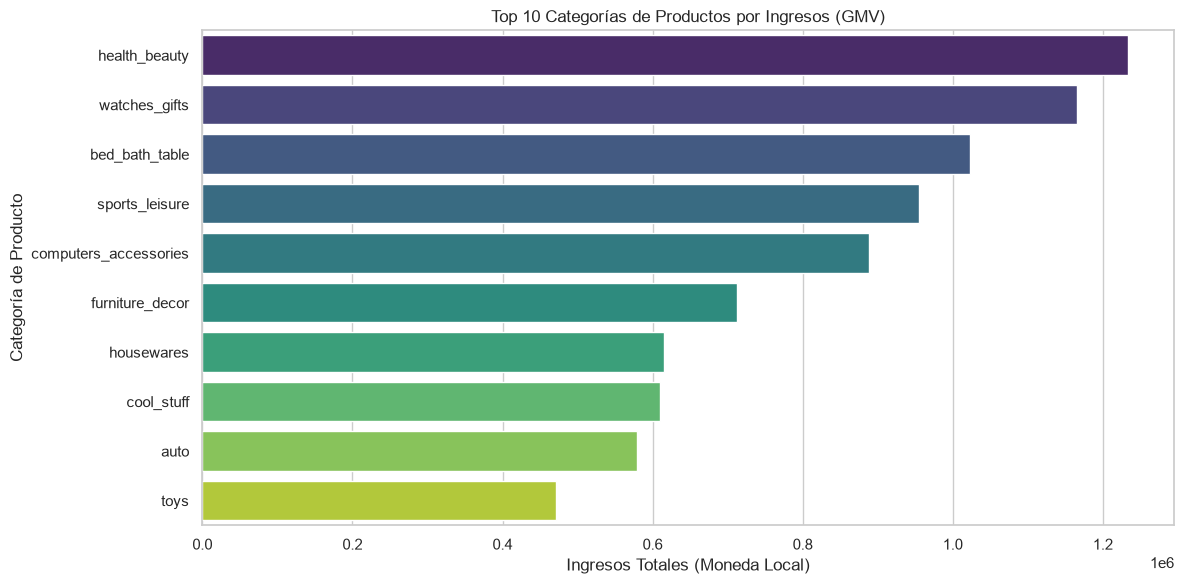

¡Éxito! Datos limpios exportados a: ../data/processed/ventas_consolidadas.csv


In [8]:
# 1. Filtrar los datos: Para ingresos, solo nos interesan los pedidos completados
df_entregados = df_consolidado[df_consolidado['order_status'] == 'delivered'].copy()

# 2. Responder Pregunta de Negocio 1: ¿Cuáles son las categorías con mayor ingreso bruto?
# Agrupamos por categoría y sumamos el precio de los productos
ingresos_categoria = df_entregados.groupby('product_category_name_english')['price'].sum().sort_values(ascending=False).head(10)

# 3. Visualizar los resultados
plt.figure(figsize=(12, 6))
sns.barplot(x=ingresos_categoria.values, y=ingresos_categoria.index, hue=ingresos_categoria.index, palette='viridis', legend=False)
plt.title('Top 10 Categorías de Productos por Ingresos (GMV)')
plt.xlabel('Ingresos Totales (Moneda Local)')
plt.ylabel('Categoría de Producto')
plt.tight_layout()
plt.show()

# 4. Seleccionar columnas clave para no sobrecargar Excel y MySQL
columnas_clave = [
    'order_id', 'customer_id', 'order_status', 
    'order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date',
    'product_id', 'price', 'freight_value', 'product_category_name_english'
]

df_exportar = df_entregados[columnas_clave]

# 5. Exportar a CSV en la carpeta "processed"
ruta_salida = '../data/processed/ventas_consolidadas.csv'
df_exportar.to_csv(ruta_salida, index=False)
print(f"¡Éxito! Datos limpios exportados a: {ruta_salida}")

In [10]:
from sqlalchemy import create_engine
import pymysql

# 1. Crear la conexión a MySQL (usuario 'root', cambia tu contraseña y el puerto si es distinto a 3306)
usuario = "root"
contraseña = "admin"  # <--- MODIFICA ESTO
host = "localhost"
base_datos = "ecommerce_olist"

# String de conexión
conexion_str = f"mysql+pymysql://{usuario}:{contraseña}@{host}/{base_datos}"
engine = create_engine(conexion_str)

print("Conexión establecida con MySQL.")

# 2. Preparar las 3 tablas respetando el modelo relacional

# Tabla Productos (eliminamos duplicados para respetar la Primary Key)
df_productos_sql = df_consolidado[['product_id', 'product_category_name_english']].drop_duplicates(subset=['product_id']).dropna(subset=['product_id'])

# Tabla Órdenes (eliminamos duplicados)
df_ordenes_sql = df_consolidado[['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date']].drop_duplicates(subset=['order_id']).dropna(subset=['order_id'])

# Tabla Detalles de Orden
df_items_sql = df_consolidado[['order_id', 'product_id', 'price', 'freight_value']].dropna(subset=['order_id', 'product_id'])

print("Dataframes preparados. Iniciando carga a la base de datos (esto puede tardar un par de minutos)...")

# 3. Cargar los datos a MySQL usando 'append' para agregar a las tablas que ya creaste con tu script SQL
df_productos_sql.to_sql(name='productos', con=engine, if_exists='append', index=False)
print("✅ Tabla 'productos' cargada.")

df_ordenes_sql.to_sql(name='ordenes', con=engine, if_exists='append', index=False)
print("✅ Tabla 'ordenes' cargada.")

df_items_sql.to_sql(name='orden_items', con=engine, if_exists='append', index=False)
print("✅ Tabla 'orden_items' cargada.")

print("¡Ingesta de datos finalizada con éxito!")

Conexión establecida con MySQL.
Dataframes preparados. Iniciando carga a la base de datos (esto puede tardar un par de minutos)...
✅ Tabla 'productos' cargada.
✅ Tabla 'ordenes' cargada.
✅ Tabla 'orden_items' cargada.
¡Ingesta de datos finalizada con éxito!


Error Absoluto Medio (MAE): 14487.57 (moneda local)


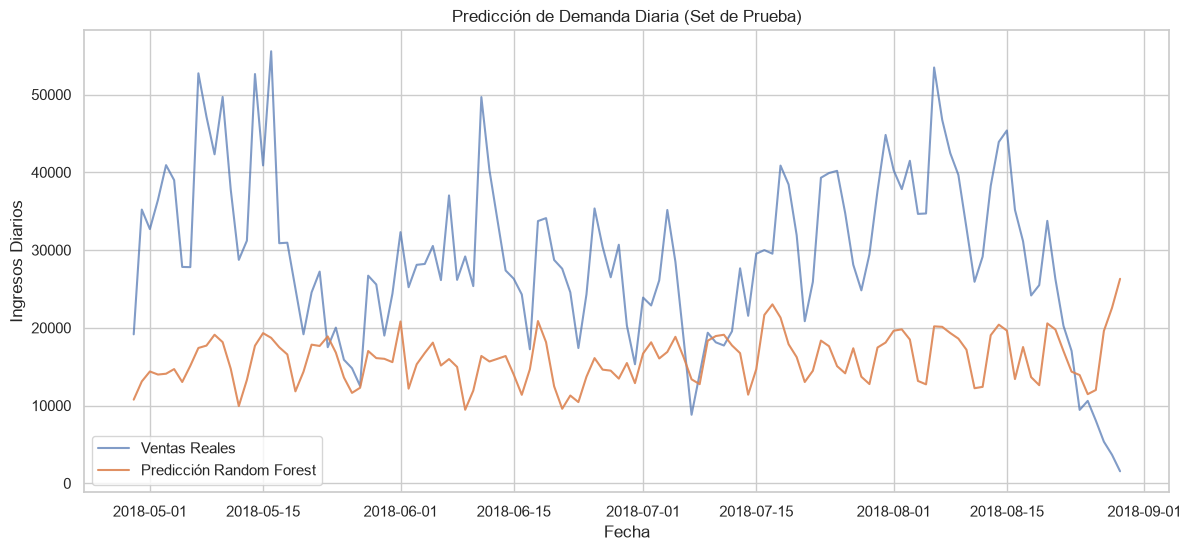

In [11]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt

# 1. Preparar datos: Agrupar ventas totales (GMV) por día
# Usamos el dataframe que filtramos en la Fase 3
df_entregados['fecha_compra'] = df_entregados['order_purchase_timestamp'].dt.date
df_demanda = df_entregados.groupby('fecha_compra')['price'].sum().reset_index()
df_demanda.columns = ['fecha', 'ventas_totales']
df_demanda['fecha'] = pd.to_datetime(df_demanda['fecha'])

# Ordenar cronológicamente (vital para series temporales)
df_demanda = df_demanda.sort_values('fecha')

# 2. Ingeniería de Características (Feature Engineering)
# Los algoritmos de ML no entienden "fechas", entienden números. 
# Extraemos el día, mes y día de la semana para encontrar patrones.
df_demanda['dia_semana'] = df_demanda['fecha'].dt.dayofweek # 0=Lunes, 6=Domingo
df_demanda['mes'] = df_demanda['fecha'].dt.month
df_demanda['dia_mes'] = df_demanda['fecha'].dt.day

# 3. Separar Variables Predictoras (X) y Variable Objetivo (y)
X = df_demanda[['dia_semana', 'mes', 'dia_mes']]
y = df_demanda['ventas_totales']

# 4. División Cronológica (Train / Test Split) - ¡Evitando Data Leakage!
# Usamos el 80% más antiguo para entrenar, y el 20% más reciente para probar.
split_index = int(len(df_demanda) * 0.8)

X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]
fechas_test = df_demanda['fecha'].iloc[split_index:]

# 5. Entrenar el modelo de Machine Learning
modelo_rf = RandomForestRegressor(n_estimators=100, random_state=42)
modelo_rf.fit(X_train, y_train)

# 6. Realizar predicciones y evaluar
predicciones = modelo_rf.predict(X_test)
mae = mean_absolute_error(y_test, predicciones)

print(f"Error Absoluto Medio (MAE): {mae:.2f} (moneda local)")

# 7. Visualizar Predicción vs Realidad
plt.figure(figsize=(14, 6))
plt.plot(fechas_test, y_test, label='Ventas Reales', alpha=0.7)
plt.plot(fechas_test, predicciones, label='Predicción Random Forest', alpha=0.9)
plt.title('Predicción de Demanda Diaria (Set de Prueba)')
plt.xlabel('Fecha')
plt.ylabel('Ingresos Diarios')
plt.legend()
plt.show()